In [14]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
import yfinance as yf

In [15]:
from datetime import datetime, timedelta

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
papel = 'VALE3.SA'
nome_modelo = f'{papel}_desval_2pct'
valorizacao = -0.02

In [33]:
# Parâmetros
DIAS_JANELA_X = 30  # janela de dados recentes que formam cada X
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [34]:
base = datetime.today().date() - timedelta(days=1)
df = pp.montar_dataset(papel, dias_total_historico=600, data_base=base, x_pct=valorizacao)
df.tail(10)

[VALE3.SA] Cache existente cobre de 2020-01-02 a 2025-05-16.
[VALE3.SA] Cache cobre período solicitado (2022-11-27 a 2025-05-15).
[VALE3.SA] Retornando 614 linhas para o período solicitado.
✅ Usando cache local: ../dados\macro_20211127_20250516.csv
[^BVSP] Cache existente cobre de 2020-01-02 a 2025-05-16.
[^BVSP] Cache cobre período solicitado (2022-11-27 a 2025-05-15).
[^BVSP] Retornando 614 linhas para o período solicitado.


,close,pct_change,vol,rsi,macd,macd_signal,macd_hist,selic,ipca,dolar,close_ibov,Target
data,,,,,,,,,,,,
2025-05-02,52.799999,-0.001135,0.015992,43.961380,-0.391573,-0.367744,-0.023829,14.25,0.43,5.6394,135134.0,0.0
2025-05-05,52.959999,0.003030,0.014125,44.820640,-0.416192,-0.377433,-0.038759,14.25,0.43,5.6520,133491.0,0.0
2025-05-06,53.000000,0.000755,0.014005,45.047501,-0.427546,-0.387456,-0.040090,14.25,0.43,5.7210,133516.0,1.0
2025-05-07,52.900002,-0.001887,0.012590,44.554348,-0.439547,-0.397874,-0.041673,14.25,0.43,5.7375,133398.0,1.0
2025-05-08,52.740002,-0.003025,0.011656,43.729459,-0.456704,-0.409640,-0.047064,14.75,0.43,5.6860,136232.0,1.0
2025-05-09,52.950001,0.003982,0.010047,45.164453,-0.448189,-0.417350,-0.030839,14.75,0.43,5.6511,136512.0,NaN
2025-05-12,54.279999,0.025118,0.010650,53.289117,-0.330314,-0.399943,0.069629,14.75,0.43,5.6822,136563.0,NaN
2025-05-13,55.169998,0.016396,0.011733,57.795474,-0.163200,-0.352594,0.189394,14.75,0.43,5.6262,138963.0,NaN
2025-05-14,54.900002,-0.004894,0.011804,56.029526,-0.051948,-0.292465,0.240517,14.75,0.43,5.6100,138423.0,NaN


In [40]:
df['Target'].value_counts()

Target
0.0    510
1.0     99
Name: count, dtype: int64

In [41]:
# Preparar X e y para treino
X, y = pp.preparar_X_y_agregado(df, DIAS_JANELA_X, dropna=True)    

X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO)

In [42]:
modelo = RandomForestClassifier(n_estimators=200,
                                        max_depth=6,
                                        min_samples_leaf=10,
                                        max_features='sqrt',
                                        random_state=42,
                                        n_jobs=-1
                                        )
modelo.fit(X_train.values, y_train.values)


RandomForestClassifier(max_depth=6, min_samples_leaf=10, n_estimators=200,
                       n_jobs=-1, random_state=42)

Avaliar e logar modelo
MLflow Run ID: b8ae9ba74a3a4a5ca1e4697824e84571 para VALE3.SA_val_4pct

--- Conjunto de Treino --- Geral

Relatório de Validação (threshold = 0.5):
              precision    recall  f1-score   support

         0.0       0.89      1.00      0.94       416
         1.0       1.00      0.26      0.41        69

    accuracy                           0.89       485
   macro avg       0.95      0.63      0.68       485
weighted avg       0.91      0.89      0.87       485

Precisão (classe 1): 1.0
Recall (classe 1): 0.2608695652173913
AUC no treino: 0.987

--- Conjunto de Treino --- Janelas
→ Threshold calibrado para recall ≥ 0.05: 0.44

Avaliação com Janela Deslizante (30 dias):
Precisão média (em 116 janelas com previsão positiva): 1.000
Recall médio: 0.183
Acurácia média: 0.910

Threshold ideal baseado em recall mínimo: 0.39

--- Conjunto de Validação --- Geral

Relatório de Validação (threshold = 0.39167634713224453):
              precision    recall  f1-score 

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\treinamento.py:226: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  resumo = df_probas.groupby('faixa').agg(


Modelo VALE3.SA_val_4pct salvo na run b8ae9ba74a3a4a5ca1e4697824e84571


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


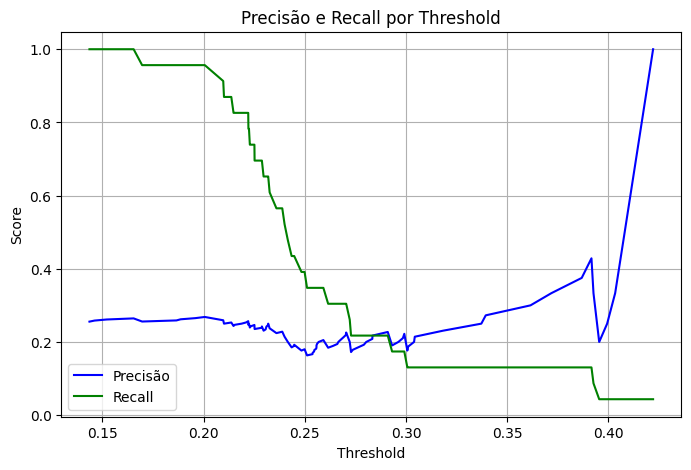

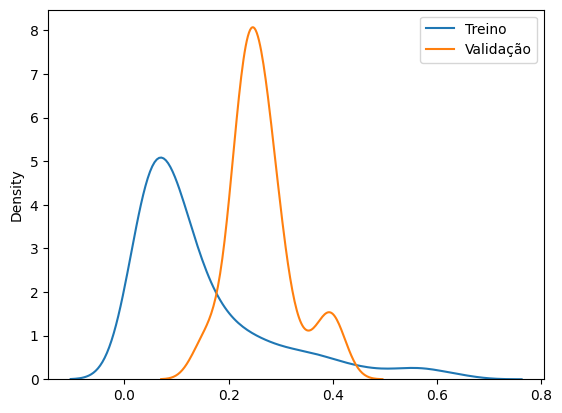

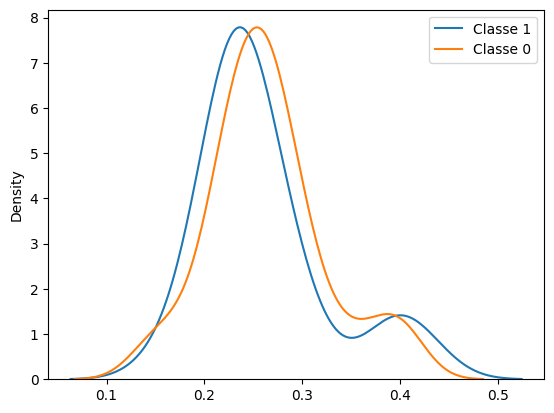

In [45]:
recall_minimo = 0.05
resultado = tr.avaliar_e_logar_modelo(modelo, papel, nome_modelo, X_train, y_train, X_validacao, y_validacao, dias_janela=DIAS_JANELA_X, valorizacao=valorizacao, dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, window_size=30)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

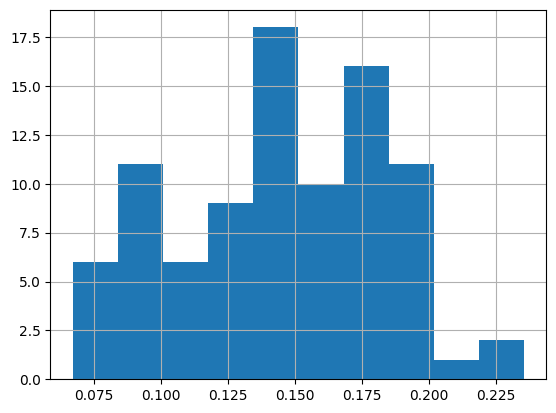

In [25]:
pd.Series(probas).hist()

# Redução de features

In [12]:
# Importâncias
importancias = pd.Series(modelo.feature_importances_, index=X.columns)
importancias = importancias.sort_values(ascending=False)


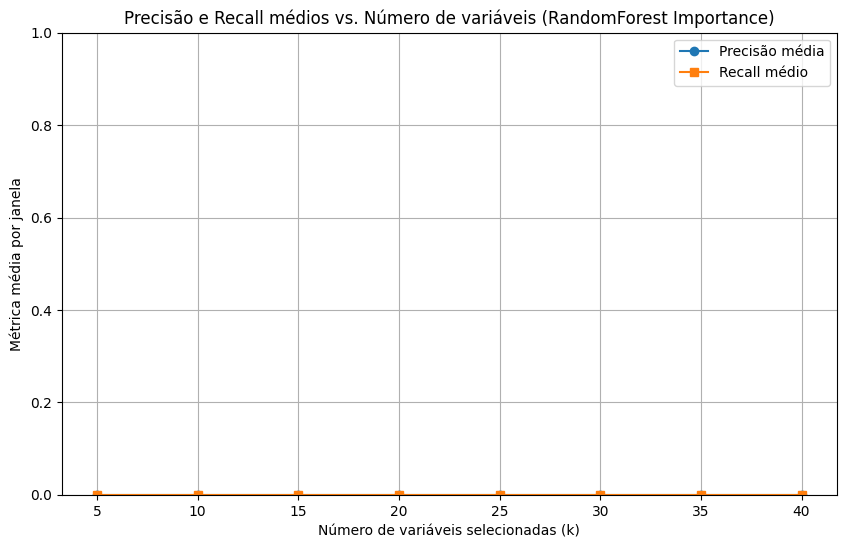

In [13]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k).index.tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            modelo.fit(X_train[colunas_selecionadas], y_train)

            y_pred = modelo.predict(X_val_teste)

            prec = precision_score(y_val_teste, y_pred, zero_division=0)
            rec = recall_score(y_val_teste, y_pred, zero_division=0)

            precisões.append(prec)
            recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, importancias)

plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (RandomForest Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()


# Features reduzidas: 20

In [26]:
n_features = 20
lista_colunas_selecionadas = importancias.head(n_features).index.tolist()
lista_colunas_selecionadas

['ibov_trend',
 'close_mean',
 'retorno_medio_pos',
 'macd_hist_ultimo',
 'retorno_std',
 'macd_signal_std',
 'close_dist_min',
 'dolar_ultimo',
 'rsi_ultimo',
 'macd_signal_mean',
 'close_std',
 'macd_hist_mean',
 'close_min',
 'close_trend',
 'ibov_std',
 'macd_std',
 'macd_ultimo',
 'close_amplitude',
 'macd_hist_abs_ultimo',
 'macd_conf_ultimo']

In [27]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [28]:
modelo_reduzido = RandomForestClassifier(n_estimators=200,
                                        max_depth=6,
                                        min_samples_leaf=10,
                                        max_features='sqrt',
                                        random_state=42,
                                        n_jobs=-1
                                        )
modelo_reduzido.fit(X_train_reduzido.values, y_train.values)


RandomForestClassifier(max_depth=6, min_samples_leaf=10, n_estimators=200,
                       n_jobs=-1, random_state=42)

Avaliar e logar modelo
MLflow Run ID: ebdd3f84b77a428dbbfeb45c4a71ed89 para VALE3.SA_desval_5pct

--- Conjunto de Treino --- Geral

Relatório de Validação (threshold = 0.5):
              precision    recall  f1-score   support

         0.0       0.88      1.00      0.94       397
         1.0       1.00      0.40      0.57        88

    accuracy                           0.89       485
   macro avg       0.94      0.70      0.75       485
weighted avg       0.90      0.89      0.87       485

Precisão (classe 1): 1.0
Recall (classe 1): 0.3977272727272727
AUC no treino: 0.975

--- Conjunto de Treino --- Janelas
→ Threshold calibrado para recall ≥ 0.1: 0.48

Avaliação com Janela Deslizante (30 dias):
Precisão média (em 218 janelas com previsão positiva): 1.000
Recall médio: 0.354
Acurácia média: 0.909

Threshold ideal baseado em recall mínimo: 0.19

--- Conjunto de Validação --- Geral

Relatório de Validação (threshold = 0.19136221197233527):
              precision    recall  f1-scor

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\OneDrive - Secretaria da Fazenda e Planejamento do Estado de São Paulo\_Pessoal\Quant\palpiteiro\scripts\treinamento.py:226: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  resumo = df_probas.groupby('faixa').agg(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


Modelo VALE3.SA_desval_5pct salvo na run ebdd3f84b77a428dbbfeb45c4a71ed89


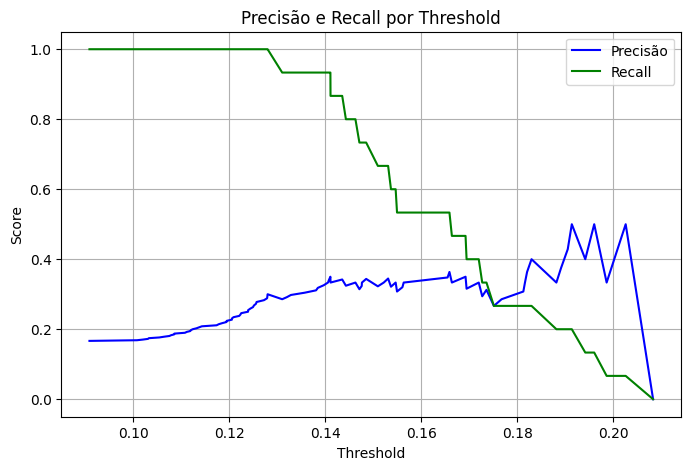

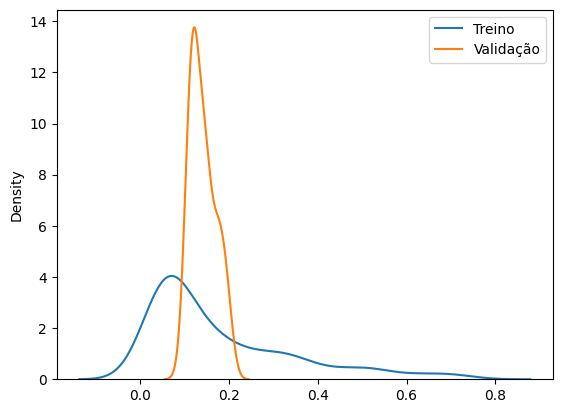

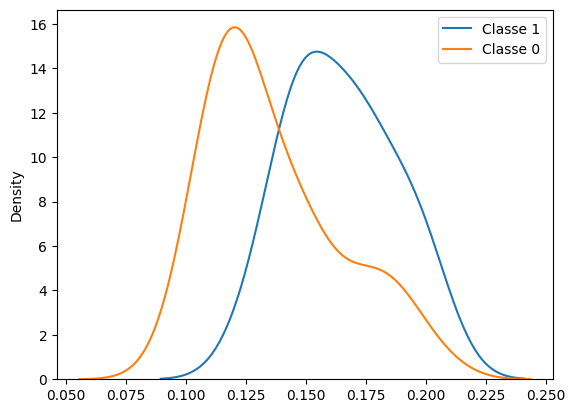

In [30]:
resultado = tr.avaliar_e_logar_modelo(modelo_reduzido, papel, nome_modelo, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela=DIAS_JANELA_X, valorizacao=valorizacao, dias_validacao=DIAS_VALIDACAO, recall_minimo=0.1, window_size=30)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

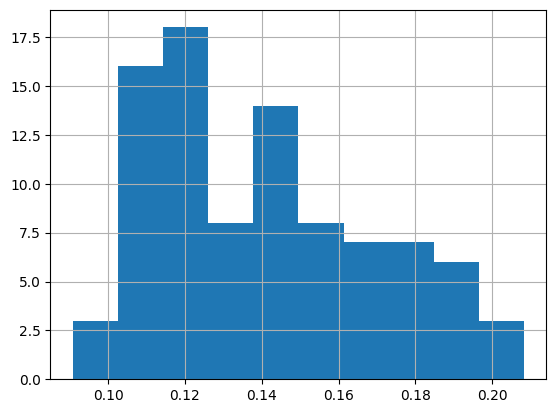

In [31]:
pd.Series(probas).hist()